<a href="https://colab.research.google.com/github/lakshanya-j/Projects/blob/main/K_MeansClusteringOnLiveSellingDataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First Five Rows:
                          status_id status_type status_published  \
0  246675545449582_1649696485147474       video   4/22/2018 6:00   
1  246675545449582_1649426988507757       photo  4/21/2018 22:45   
2  246675545449582_1648730588577397       video   4/21/2018 6:17   
3  246675545449582_1648576705259452       photo   4/21/2018 2:29   
4  246675545449582_1645700502213739       photo   4/18/2018 3:22   

   num_reactions  num_comments  num_shares  num_likes  num_loves  num_wows  \
0            529           512         262        432         92         3   
1            150             0           0        150          0         0   
2            227           236          57        204         21         1   
3            111             0           0        111          0         0   
4            213             0           0        204          9         0   

   num_hahas  num_sads  num_angrys  Column1  Column2  Column3  Column4  
0          1         1          

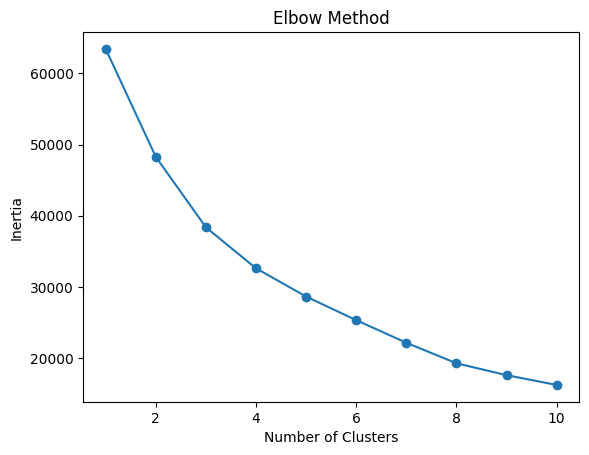


Comparing Different Numbers of Clusters:
Clusters: 2 Silhouette Score: 0.816
Clusters: 3 Silhouette Score: 0.75
Clusters: 4 Silhouette Score: 0.757
Clusters: 5 Silhouette Score: 0.761
Clusters: 6 Silhouette Score: 0.714
Clusters: 7 Silhouette Score: 0.718
Clusters: 8 Silhouette Score: 0.712
Clusters: 9 Silhouette Score: 0.71
Clusters: 10 Silhouette Score: 0.693

Records in Each Cluster:
Cluster
0    6405
2     372
1     273
Name: count, dtype: int64

Average Values of Each Cluster:
         num_reactions  num_comments  num_shares    num_likes   num_loves  \
Cluster                                                                     
0           113.854489    106.228571   21.711319   105.294770    7.464637   
1           786.871795   3217.948718  508.300366   606.293040  149.344322   
2          1823.311828     61.333333   11.645161  1817.534946    3.104839   

          num_wows  num_hahas  num_sads  num_angrys  
Cluster                                              
0         0.549727

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv('Live.csv')

print("First Five Rows:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

df = df.dropna(axis=1, how='all')
df = df.select_dtypes(include='number')
df = df.fillna(df.median())

print("\nData After Cleaning:")
print(df.isnull().sum())

scaler = StandardScaler()
data = scaler.fit_transform(df)

inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(data)
    inertia.append(model.inertia_)

plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

print("\nComparing Different Numbers of Clusters:")

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(data)
    score = silhouette_score(data, labels)
    print("Clusters:", k, "Silhouette Score:", round(score, 3))

model = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = model.fit_predict(data)

print("\nRecords in Each Cluster:")
print(df['Cluster'].value_counts())

print("\nAverage Values of Each Cluster:")
print(df.groupby('Cluster').mean())

print("\nConclusion:")
print("The Live Selling dataset contains information about Facebook post engagement, including reactions, comments and shares. K-Means clustering was used to group similar posts. The Elbow Method and Silhouette Score helped compare different numbers of clusters. This project helped me understand how machine learning can identify patterns in data.")